In [6]:
import os
import matplotlib.pyplot as plt

import rasterio 
import pandas as pd
import geopandas as gpd
from scipy.ndimage import gaussian_filter

from torch import Tensor

In [2]:
import sys
sys.path.append('../')
from utils import get_tiles_as_gdf, extract_sample, get_window

In [68]:
idx = '2000003'

forestloss_dir = '/home/jan/Documents/EPFL/project_2/data/forestloss_patches/all/'

In [71]:
path = os.path.join(forestloss_dir, f'{idx}.tif')
with rasterio.open(path) as source:
    #data = source.read()
    forestloss = source.read().astype('float').squeeze()
    min_val = 2000
    max_val = 2020
    forestloss[(forestloss < min_val) | (forestloss > max_val)] = 0
    forestloss[(forestloss >= min_val) & (forestloss <= max_val)] = 1

    forestloss = gaussian_filter(forestloss, sigma=1)
    forestloss = Tensor(forestloss)
    



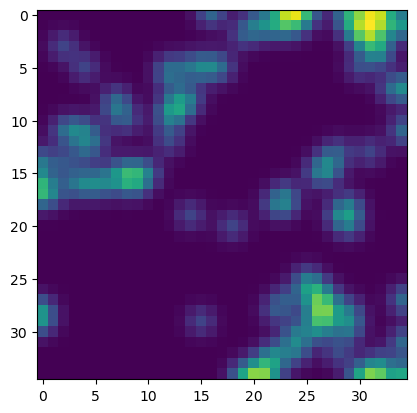

In [72]:
plt.imshow(fordestloss)

In [67]:
data.shape

(35, 35)

In [64]:
from torchvision.models import resnet18, resnet34,resnet50


In [65]:
net = resnet18(weights=None)

In [66]:
net

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [73]:
img_path = '/home/jan/Documents/EPFL/project_2/data/images/dataset_v3/four_images/2000003/20220105T041139_20220105T042133_T47QKF_opaque_clouds_0_cirrus_0_CLOUD_PERC_0.tif'


In [74]:
with rasterio.open(img_path) as source:
    data = source.read()

In [90]:
img = data.transpose(1, 2, 0)[:,:,[2,1,0]]
img = img/img.max()

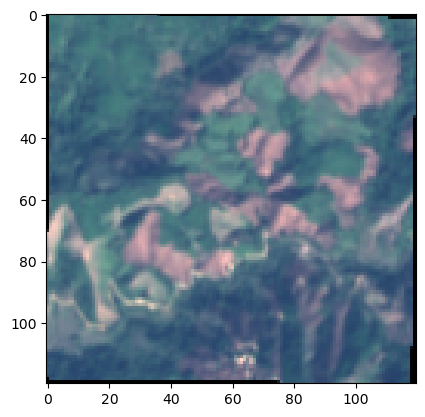

In [91]:
plt.imshow(img)

## Producing correct TMF tiles that align with the images I use as inputs

In [ ]:
'''- just iterate through labels.csv, for each row
    - grab the point
    - make a 1km square around
    - use that as a window to read TMF
    - write to file'''

In [4]:
forestloss_dir = '../../Vancutsem_yearloss'
forestloss_tiles = get_tiles_as_gdf(forestloss_dir)

In [67]:
df = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/labels/dataset_v3/labels.csv')
df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])
gdf = gpd.GeoDataFrame(df)

                       


In [96]:
for idx, row in gdf.iterrows():
    
    #Convert geometry to a gdf to project to meters
    _gdf = gpd.GeoDataFrame({'geometry': [row['geometry']]})
    _gdf.crs = 4326
    utm = _gdf.estimate_utm_crs()
    _gdf = _gdf.to_crs(utm)
    
    #Apply buffer 
    _gdf['geometry'] = _gdf.geometry.buffer(500, cap_style=3)
    
    #Convert back to 4326    
    _gdf = _gdf.to_crs(4326)
    
    poly = _gdf.geometry.values[0]
    
    filename = forestloss_tiles.loc[forestloss_tiles.intersects(poly)]['filename'].values[0]
    
    with rasterio.open(filename) as src:
        tmf_patch = src.read(window=rasterio.windows.from_bounds(
            _gdf.bounds.minx.values[0],
            _gdf.bounds.miny.values[0],
            _gdf.bounds.maxx.values[0],
            _gdf.bounds.maxy.values[0],
            src.transform
        ))
    

    break

In [100]:
row

geometry    POINT (-6.726781621781269 5.505369307436387)
driver                                             cocoa
sampleid                                         3039418
split                                              train
Name: 0, dtype: object

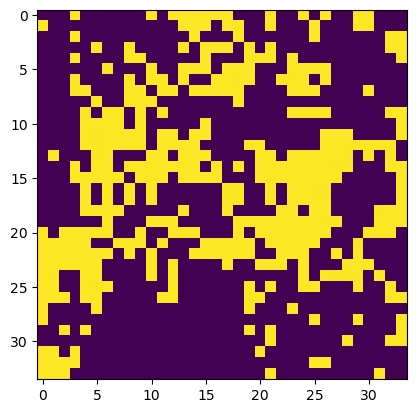

In [99]:
plt.imshow(tmf_patch.squeeze())